# Activity Data — Exploratory Data Analysis

## 1. Objective

This notebook explores the `activity_data` table from the smartwatch dataset. The goal is to understand the table's completeness, inspect daily activity distributions, compare activity patterns across users and time, and investigate unusual observations without assuming that they are errors.

### Questions explored
- How complete is `floors_climbed`, and does missingness differ by user or weekday?
- How are daily steps, distance, active time, and intensity durations distributed?
- Which users have the highest average recorded activity?
- How do average daily steps change month by month?
- Are unusual activity values or zero-activity records potentially related to data-coverage issues?

### Scope and interpretation
This is exploratory analysis, not a medical assessment. High or zero values are observations to investigate, not automatically errors. Missing measurements are kept distinct from measured zeros. Any explanation for missing data remains tentative unless supported by additional evidence.


## 2. Load the data and dependencies

The next cell runs `data_profile_generator.ipynb`, which is expected to create the shared `dataframes` dictionary and supporting variables such as `activity_data`, `pd`, and `plt`. Run the profile notebook successfully before continuing.

**Dependency:** `data_profile_generator.ipynb` must be available in the notebook's working directory. The notebook should be run from an environment where its database/data-loading setup is configured.


In [1]:
%run -i data_profile_generator.ipynb > $null

Loaded body_battery_activity_events_data: 448 rows
Loaded activity_data: 987 rows
Loaded goals_data: 987 rows
Loaded heart_rate_values_data: 961 rows
Loaded kilocalories_data: 987 rows
Loaded overall_sleep_data: 299 rows
Loaded sleep_data: 299 rows
Loaded steps_data: 987 rows
Loaded stress_data: 987 rows
Loaded sleep_level_events_data: 18,402 rows
Loaded body_battery_sample_data: 315,848 rows
Loaded stress_level_sample_data: 460,975 rows
Loaded heart_rate_sample_data: 4,912,004 rows
activity_data: (987, 16)
body_battery_activity_events_data: (448, 14)
body_battery_sample_data: (315848, 12)
goals_data: (987, 13)
heart_rate_sample_data: (4912004, 12)
heart_rate_values_data: (961, 14)
kilocalories_data: (987, 12)
overall_sleep_data: (299, 12)
sleep_data: (299, 17)
sleep_level_events_data: (18402, 13)
steps_data: (987, 12)
stress_data: (987, 19)
stress_level_sample_data: (460975, 12)
DATABASE INVENTORY


,table,rows,columns,memory_MB
0,activity_data,987,16,0.28
1,body_battery_activity_events_data,448,14,0.14
2,body_battery_sample_data,315848,12,78.57
3,goals_data,987,13,0.25
4,heart_rate_sample_data,4912004,12,1222.59
5,heart_rate_values_data,961,14,0.25
6,kilocalories_data,987,12,0.25
7,overall_sleep_data,299,12,0.09
8,sleep_data,299,17,0.19
9,sleep_level_events_data,18402,13,5.65



TABLE: activity_data
Shape: (987, 16)


,column,dtype,missing_count,missing_percent,unique_values
0,additional_id,str,0,0.00,987
1,sdv_user_id,int64,0,0.00,8
2,sdv_group_id,int64,0,0.00,3
3,sdv_data_type,str,0,0.00,1
4,calendar_date,object,0,0.00,251
5,start_measure_period_sec,int64,0,0.00,259
6,end_measure_period_sec,int64,0,0.00,272
7,duration_measure_period_sec,int64,0,0.00,17
8,week_nr,int64,0,0.00,37
9,week_day,int64,0,0.00,7


First 3 rows:


...

,count,mean,std,min,25%,50%,75%,max
sdv_user_id,987.0,4.200755e+03,2.156566e+02,3.724000e+03,4.274000e+03,4.286000e+03,4.306000e+03,4.408000e+03
sdv_group_id,987.0,7.553390e+03,5.202031e-01,7.552000e+03,7.553000e+03,7.553000e+03,7.554000e+03,7.554000e+03
start_measure_period_sec,987.0,1.779292e+09,5.253043e+06,1.767222e+09,1.776118e+09,1.779401e+09,1.783462e+09,1.788818e+09
end_measure_period_sec,987.0,1.779378e+09,5.252706e+06,1.767308e+09,1.776204e+09,1.779487e+09,1.783548e+09,1.788905e+09
duration_measure_period_sec,987.0,8.577684e+04,6.286301e+03,3.000000e+02,8.640000e+04,8.640000e+04,8.640000e+04,9.000000e+04
week_nr,987.0,2.095846e+01,8.694225e+00,1.000000e+00,1.600000e+01,2.100000e+01,2.800000e+01,3.700000e+01
week_day,987.0,4.020263e+00,1.990748e+00,1.000000e+00,2.000000e+00,4.000000e+00,6.000000e+00,7.000000e+00
steps,987.0,6.802246e+03,5.643962e+03,0.000000e+00,3.151000e+03,5.302000e+03,8.851500e+03,4.702500e+04
steps_goal,987.0,8.027082e+03,3.617580e+03,2.780000e+03,5.985000e+03,8.000000e+03,1.000000e+04,3.000000e+04



NUMERICAL SUMMARY: stress_data


,count,mean,std,min,25%,50%,75%,max
sdv_user_id,987.0,4.200755e+03,2.156566e+02,3.724000e+03,4.274000e+03,4.286000e+03,4.306000e+03,4.408000e+03
sdv_group_id,987.0,7.553390e+03,5.202031e-01,7.552000e+03,7.553000e+03,7.553000e+03,7.554000e+03,7.554000e+03
start_measure_period_sec,987.0,1.779292e+09,5.253043e+06,1.767222e+09,1.776118e+09,1.779401e+09,1.783462e+09,1.788818e+09
end_measure_period_sec,987.0,1.779378e+09,5.252706e+06,1.767308e+09,1.776204e+09,1.779487e+09,1.783548e+09,1.788905e+09
duration_measure_period_sec,987.0,8.577684e+04,6.286301e+03,3.000000e+02,8.640000e+04,8.640000e+04,8.640000e+04,9.000000e+04
week_nr,987.0,2.095846e+01,8.694225e+00,1.000000e+00,1.600000e+01,2.100000e+01,2.800000e+01,3.700000e+01
week_day,987.0,4.020263e+00,1.990748e+00,1.000000e+00,2.000000e+00,4.000000e+00,6.000000e+00,7.000000e+00
average_stress_level,987.0,3.243161e+01,1.227302e+01,-1.000000e+00,2.500000e+01,3.200000e+01,3.800000e+01,8.600000e+01
max_stress_level,960.0,9.436667e+01,6.449688e+00,3.200000e+01,9.300000e+01,9.600000e+01,9.900000e+01,1.000000e+02
stress_duration_sec,960.0,2.912775e+04,1.269687e+04,6.000000e+01,1.869000e+04,2.976000e+04,3.954000e+04,6.840000e+04



NUMERICAL SUMMARY: stress_level_sample_data


,count,mean,std,min,25%,50%,75%,max
sdv_user_id,460975.0,4.199134e+03,2.170695e+02,3.724000e+03,4.274000e+03,4.286000e+03,4.306000e+03,4.408000e+03
sdv_group_id,460975.0,7.553380e+03,5.174617e-01,7.552000e+03,7.553000e+03,7.553000e+03,7.554000e+03,7.554000e+03
start_measure_period_sec,460975.0,1.779330e+09,5.240222e+06,1.767222e+09,1.776118e+09,1.779401e+09,1.783548e+09,1.788818e+09
end_measure_period_sec,460975.0,1.779416e+09,5.240121e+06,1.767308e+09,1.776204e+09,1.779487e+09,1.783634e+09,1.788905e+09
duration_measure_period_sec,460975.0,8.622615e+04,2.830754e+03,3.000000e+02,8.640000e+04,8.640000e+04,8.640000e+04,9.000000e+04
week_nr,460975.0,2.102193e+01,8.675071e+00,1.000000e+00,1.600000e+01,2.100000e+01,2.800000e+01,3.700000e+01
week_day,460975.0,4.013734e+00,1.988962e+00,1.000000e+00,2.000000e+00,4.000000e+00,6.000000e+00,7.000000e+00
sample_point_sec,460975.0,1.779373e+09,5.240262e+06,1.767222e+09,1.776169e+09,1.779430e+09,1.783583e+09,1.788905e+09
stress_level,460975.0,2.160563e+01,2.401784e+01,-2.000000e+00,-1.000000e+00,1.700000e+01,3.400000e+01,1.000000e+02


## 3. Initial inspection: `floors_climbed`

The first checks focus on the `floors_climbed` column because the initial profile showed substantial missingness. The following cells count observed values, inspect the table's shape and data type, summarize the distribution, and show the most common values.

**Interpretation note:** `count()` returns the number of non-null values, not the number of null values. The label in the original first print statement says “Number of null values,” but its expression uses `.count()` and therefore counts non-null entries. The later checks using `.isna()` and `.notna()` provide the clearer missing-versus-available counts.


In [2]:
print("Number of null values : ",activity_data["floors_climbed"].count())
print("Unique values : ",len(activity_data["floors_climbed"].unique()) - 1)
print("Number of non null values : ", activity_data["floors_climbed"].dropna().count())
print("percentage of null values : ",round((987 - activity_data["floors_climbed"].dropna().count()) / 987 * 100 , 2),"%")



Number of null values :  429
Unique values :  50
Number of non null values :  429
percentage of null values :  56.53 %


In [4]:
activity_data.head()

,additional_id,sdv_user_id,sdv_group_id,sdv_data_type,calendar_date,start_measure_period_sec,end_measure_period_sec,duration_measure_period_sec,week_nr,week_day,distance_in_meters,steps,floors_climbed,active_time_sec,moderate_intensity_duration_sec,vigorous_intensity_duration_sec
0,x6607386-6a1a0c60-13254,4408,7552,garmin_type,2026-05-30,1780092000,1780170420,78420,22,6,11826,16204,NaN,13439,1140,0
1,x6607386-6a18bae0-15180-0,4408,7552,garmin_type,2026-05-29,1780005600,1780092000,86400,22,5,60,82,NaN,300,0,0
2,x6607386-6a176960-15180-0,4408,7552,garmin_type,2026-05-28,1779919200,1780005600,86400,22,4,2180,2987,NaN,3966,420,60
3,x6607386-6a1617e0-15180-0,4408,7552,garmin_type,2026-05-27,1779832800,1779919200,86400,22,3,4946,6777,NaN,8897,0,0
4,x6607386-6a14c660-15180-0,4408,7552,garmin_type,2026-05-26,1779746400,1779832800,86400,22,2,6089,8343,NaN,8389,180,0


In [5]:
df = dataframes["activity_data"]

# Basic overview
print("Shape:", df.shape)
print("Data type:", df["floors_climbed"].dtype)

# Missing vs non-missing
print("Total rows:", len(df))
print("Missing:", df["floors_climbed"].isna().sum())
print("Available:", df["floors_climbed"].notna().sum())
print("Missing %:", df["floors_climbed"].isna().mean() * 100)

# Distribution of recorded values
print(df["floors_climbed"].describe())

# Actual recorded values and their frequency
print(df["floors_climbed"].value_counts(dropna=False).head(20))

Shape: (987, 16)
Data type: float64
Total rows: 987
Missing: 558
Available: 429
Missing %: 56.53495440729483
count    429.000000
mean       9.853147
std       13.265596
min        0.000000
25%        2.000000
50%        6.000000
75%       13.000000
max      118.000000
Name: floors_climbed, dtype: float64
floors_climbed
NaN     558
0.0      76
3.0      30
4.0      29
1.0      28
2.0      26
9.0      18
5.0      18
7.0      17
6.0      17
8.0      16
12.0     16
13.0     16
10.0     13
11.0      9
15.0      8
16.0      7
17.0      7
22.0      7
18.0      7
Name: count, dtype: int64


### Missingness by user and weekday

These groupings test whether missing floor counts are concentrated in particular users or weekdays. A high missing percentage for a user may reflect differences in device support, collection, or export behavior; this table alone cannot identify the cause.

Previously observed result: `floors_climbed` was missing for approximately **56.5%** of the 987 rows overall. Several users had no floor values recorded, while other users had values available. Missingness by weekday was approximately **56–57%**, so weekday alone did not explain the pattern.

**Data-handling decision:** retain missing floor counts as missing. Do not replace them with zero unless the data source confirms that a missing value means zero floors climbed.


In [6]:

df = dataframes["activity_data"]

# Missing floor counts by user
print(
    df.groupby("sdv_user_id")["floors_climbed"]
      .agg(
          total_rows="size",
          available="count",
          average="mean"
      )
)

# Missing floor counts by weekday
print("\nMissing percentage by weekday:")

print(
    df.assign(
        floors_missing=df["floors_climbed"].isna()
    )
    .groupby("week_day")["floors_missing"]
    .mean()
    .mul(100)
    .round(2)
)


             total_rows  available    average
sdv_user_id                                  
3724                 58         58  12.965517
3760                122        122  20.139344
4273                 25          0        NaN
4274                250          0        NaN
4286                126          0        NaN
4306                249        249   4.088353
4350                141          0        NaN
4408                 16          0        NaN

Missing percentage by weekday:
week_day
1    56.52
2    56.12
3    56.83
4    57.04
5    56.55
6    56.16
7    56.52
Name: floors_missing, dtype: float64


### Compare missingness across activity variables

This cell compares the percentage of missing values for distance, steps, floors, active time, and moderate/vigorous intensity duration, separately for each user.

The comparison helps determine whether the missingness is isolated to floors or affects several activity measurements at once. In the current exploration, the other listed activity measures were complete while `floors_climbed` was missing for some users. This supports describing the issue as **measurement-specific missingness**, while leaving its cause unconfirmed.


In [7]:
df = dataframes["activity_data"]

# Compare missingness across activity columns for each user
cols = [
    "distance_in_meters",
    "steps",
    "floors_climbed",
    "active_time_sec",
    "moderate_intensity_duration_sec",
    "vigorous_intensity_duration_sec"
]

missing_by_user = (
    df.groupby("sdv_user_id")[cols]
      .agg(lambda col: col.isna().mean() * 100)
      .round(1)
)

print(missing_by_user)

             distance_in_meters  steps  floors_climbed  active_time_sec  \
sdv_user_id                                                               
3724                        0.0    0.0             0.0              0.0   
3760                        0.0    0.0             0.0              0.0   
4273                        0.0    0.0           100.0              0.0   
4274                        0.0    0.0           100.0              0.0   
4286                        0.0    0.0           100.0              0.0   
4306                        0.0    0.0             0.0              0.0   
4350                        0.0    0.0           100.0              0.0   
4408                        0.0    0.0           100.0              0.0   

             moderate_intensity_duration_sec  vigorous_intensity_duration_sec  
sdv_user_id                                                                    
3724                                     0.0                              0.0  
3760     

## 4. Descriptive statistics and distributions

The summary table reports count, mean, standard deviation, quartiles, minimum, and maximum for the main activity measures.

- `steps`: daily step count.
- `distance_in_meters`: recorded distance in metres.
- `active_time_sec`: active time in seconds.
- `moderate_intensity_duration_sec`: moderate-intensity duration in seconds.
- `vigorous_intensity_duration_sec`: vigorous-intensity duration in seconds.

The histograms show the distributions of daily steps and moderate-intensity activity (converted from seconds to minutes for readability).

### How to read these results
- The **mean** is sensitive to unusually large values.
- The **median** is the middle observation and is more robust to extreme values.
- The **standard deviation** describes the spread of values around the mean.
- A right-skewed distribution has a long tail of relatively large values.

Previously observed results showed right-skew in daily steps and moderate-intensity duration, with many low or zero moderate-activity values. These patterns are reasons to examine the data, not proof that any record is invalid.


In [9]:
df = dataframes["activity_data"]

activity_cols = [
    "steps",
    "distance_in_meters",
    "active_time_sec",
    "moderate_intensity_duration_sec",
    "vigorous_intensity_duration_sec"
]

print(df[activity_cols].describe().T.round(2))

                                 count     mean      std  min     25%     50%  \
steps                            987.0  6802.25  5643.96  0.0  3151.0  5302.0   
distance_in_meters               987.0  6651.42  6348.73  0.0  2590.0  4386.0   
active_time_sec                  987.0  6482.64  4286.54  0.0  3826.0  5770.0   
moderate_intensity_duration_sec  987.0  1107.36  2133.75  0.0     0.0   180.0   
vigorous_intensity_duration_sec  987.0   671.55  1494.19  0.0     0.0     0.0   

                                    75%      max  
steps                            8851.5  47025.0  
distance_in_meters               8457.0  44783.0  
active_time_sec                  8213.0  33245.0  
moderate_intensity_duration_sec  1380.0  18840.0  
vigorous_intensity_duration_sec   600.0  16740.0  


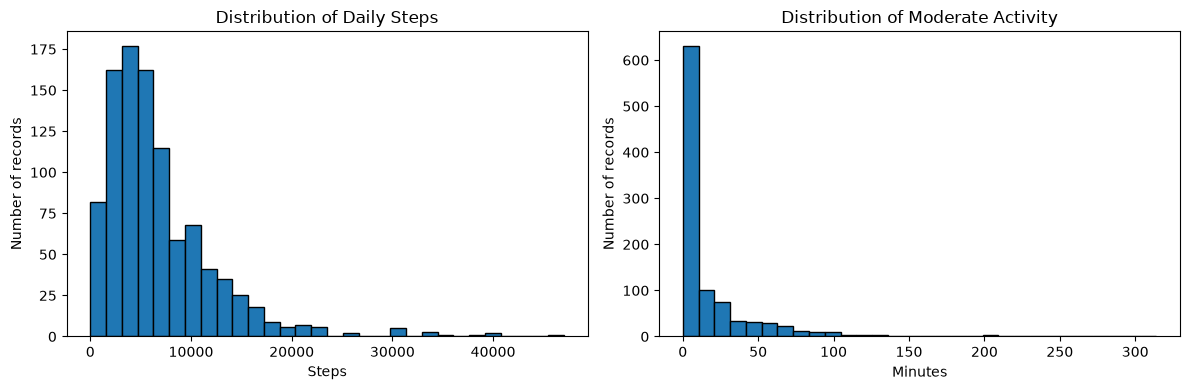

In [10]:


df = dataframes["activity_data"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["steps"], bins=30, edgecolor="black")
axes[0].set_title("Distribution of Daily Steps")
axes[0].set_xlabel("Steps")
axes[0].set_ylabel("Number of records")

axes[1].hist(
    df["moderate_intensity_duration_sec"] / 60,
    bins=30,
    edgecolor="black"
)
axes[1].set_title("Distribution of Moderate Activity")
axes[1].set_xlabel("Minutes")
axes[1].set_ylabel("Number of records")

plt.tight_layout()
plt.show()


## 5. Investigate unusually high activity records

The next cell lists the ten highest step counts and the ten longest moderate-intensity durations. It provides user IDs and dates so unusually high values can be checked in context.

An extreme value can be genuine (for example, a very active day) or can result from a data issue. Before removing any observation, compare related measures such as distance and activity duration, inspect the date, and check whether the record is plausible in context.

In this dataset, user **4286** had several of the largest step counts, including a recorded maximum of **47,025 steps** on 2026-07-31. This is an unusually high observation worth contextual inspection, but it should not be automatically deleted.


In [11]:

df = dataframes["activity_data"]

cols = [
    "sdv_user_id",
    "calendar_date",
    "steps",
    "distance_in_meters",
    "moderate_intensity_duration_sec",
    "vigorous_intensity_duration_sec"
]

print("Top 10 step counts:")
display(
    df.nlargest(10, "steps")[cols]
)

print("\nTop 10 moderate activity durations:")
display(
    df.nlargest(10, "moderate_intensity_duration_sec")[cols]
)


Top 10 step counts:


,sdv_user_id,calendar_date,steps,distance_in_meters,moderate_intensity_duration_sec,vigorous_intensity_duration_sec
641,4286,2026-07-31,47025,25632,18240,1800
643,4286,2026-07-30,40315,22136,12060,780
658,4286,2026-07-22,39531,21241,18840,960
649,4286,2026-07-27,39053,20931,11220,1800
651,4286,2026-07-26,36051,19143,14040,2040
665,4286,2026-07-19,34166,17750,10260,1500
656,4286,2026-07-23,34072,17797,12300,1320
645,4286,2026-07-29,33262,16572,11520,2460
666,4286,2026-07-18,30915,15532,9060,2160
663,4286,2026-07-20,30678,16290,10500,720



Top 10 moderate activity durations:


,sdv_user_id,calendar_date,steps,distance_in_meters,moderate_intensity_duration_sec,vigorous_intensity_duration_sec
658,4286,2026-07-22,39531,21241,18840,960
641,4286,2026-07-31,47025,25632,18240,1800
651,4286,2026-07-26,36051,19143,14040,2040
671,4286,2026-07-16,30674,15957,13680,540
813,4286,2026-05-05,22298,11878,13440,120
132,4350,2026-07-18,14622,18195,12360,3900
656,4286,2026-07-23,34072,17797,12300,1320
673,4286,2026-07-15,30645,16730,12120,2640
643,4286,2026-07-30,40315,22136,12060,780
645,4286,2026-07-29,33262,16572,11520,2460


## 6. Compare activity between users

This aggregation calculates each user's number of records, average and median steps, maximum steps, average distance, and average moderate-intensity duration in minutes.

These are **descriptive comparisons**, not necessarily fair rankings of overall activity: users have different numbers of recorded days and may have different coverage gaps. Always consider `records` alongside the averages, and avoid interpreting a short observation period as representative of a person's usual behavior.


In [12]:

df = dataframes["activity_data"]

user_activity = (
    df.groupby("sdv_user_id")
      .agg(
          records=("steps", "count"),
          avg_steps=("steps", "mean"),
          median_steps=("steps", "median"),
          max_steps=("steps", "max"),
          avg_distance_m=("distance_in_meters", "mean"),
          avg_moderate_min=(
              "moderate_intensity_duration_sec",
              lambda x: x.mean() / 60
          )
      )
      .round(2)
)

display(user_activity.sort_values("avg_steps", ascending=False))


,records,avg_steps,median_steps,max_steps,avg_distance_m,avg_moderate_min
sdv_user_id,,,,,,
3760,122,12126.40,11896.0,22757,13532.68,30.07
4286,126,10357.21,5998.5,47025,7478.12,50.21
3724,58,9146.38,7257.5,22108,7339.12,25.21
4408,16,7254.88,6424.5,19807,5302.69,3.19
4273,25,6427.08,6808.0,12131,5718.84,2.92
4306,249,5854.84,4786.0,21023,6669.37,11.00
4274,250,4511.12,4321.5,15205,4396.47,6.04
4350,141,3805.03,3232.0,14622,3960.60,16.93


## 7. Explore monthly step trends

The monthly chart plots each user's average daily steps by month. It can help reveal changes over time, but it is affected by the dates and number of records available for each user.

### Observations from the current exploration
- User **3760** showed relatively stable average daily steps of roughly 11,000–13,000 across several months.
- User **4286** showed very high average steps in July 2026, followed by a sharp decline in August.
- Other users showed lower averages or fluctuations over their available periods.

These are observed patterns in the recorded data. They should not be interpreted as definite changes in real-world behavior until recording coverage has been checked.


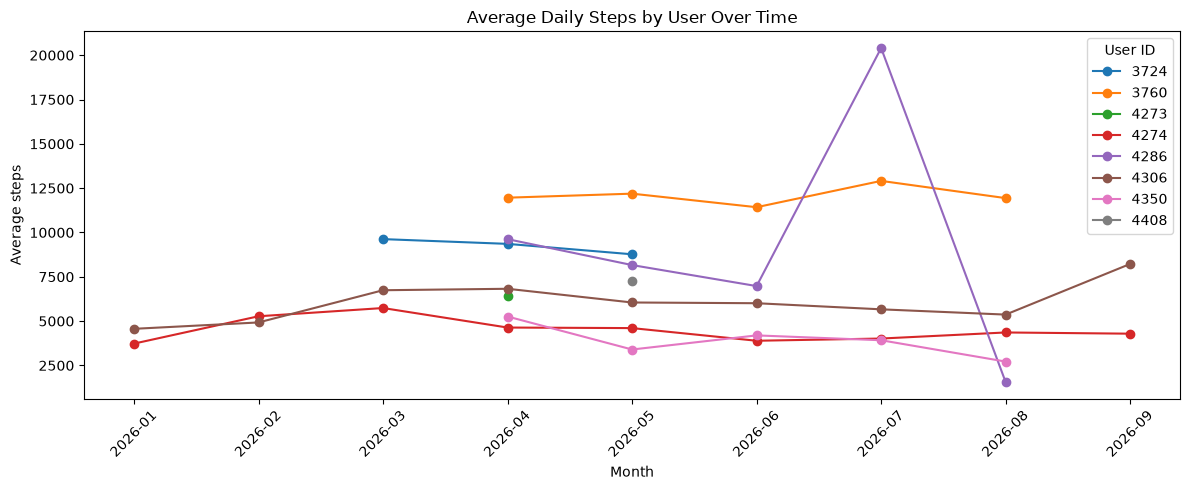

In [13]:

df = dataframes["activity_data"].copy()

df["calendar_date"] = pd.to_datetime(df["calendar_date"])
df["month"] = df["calendar_date"].dt.to_period("M").astype(str)

monthly_steps = (
    df.groupby(["sdv_user_id", "month"])["steps"]
      .mean()
      .unstack("sdv_user_id")
)

monthly_steps.plot(figsize=(12, 5), marker="o")
plt.title("Average Daily Steps by User Over Time")
plt.xlabel("Month")
plt.ylabel("Average steps")
plt.xticks(rotation=45)
plt.legend(title="User ID")
plt.tight_layout()
plt.show()


## 8. Case study: user 4286 in July and August 2026

The following cells inspect monthly step statistics and individual August records for user 4286. The aim is to determine whether the sharp month-to-month decline reflects a consistent reduction in recorded activity or a potential recording gap.

The earlier results showed:
- July: 31 records, mean **20,403.8 steps/day**, median **20,570**, maximum **47,025**.
- August: 15 records, mean **1,556 steps/day**, median **0**, maximum **12,411**.
- In August, **11 of the 15 records had zero steps**, and only 15 dates had records in the month.

This is a strong reason to inspect data coverage before claiming that the user's activity genuinely declined. A zero-step record is not the same as a missing date, and neither one alone tells us why no activity was recorded.


In [14]:

df = dataframes["activity_data"].copy()

df["calendar_date"] = pd.to_datetime(df["calendar_date"])

user = df[df["sdv_user_id"] == 4286]

for month in ["2026-07", "2026-08"]:
    monthly = user[
        user["calendar_date"].dt.to_period("M").astype(str) == month
    ]

    print(f"\n{month}")
    print("Number of records:", len(monthly))
    print(monthly["steps"].describe())

    display(
        monthly.sort_values("steps", ascending=False)[
            ["calendar_date", "steps", "distance_in_meters"]
        ].head(5)
    )



2026-07
Number of records: 31
count       31.000000
mean     20403.774194
std      14246.966184
min       2527.000000
25%       5920.500000
50%      20570.000000
75%      32088.500000
max      47025.000000
Name: steps, dtype: float64


,calendar_date,steps,distance_in_meters
641,2026-07-31,47025,25632
643,2026-07-30,40315,22136
658,2026-07-22,39531,21241
649,2026-07-27,39053,20931
651,2026-07-26,36051,19143



2026-08
Number of records: 15
count       15.000000
mean      1556.000000
std       4000.964759
min          0.000000
25%          0.000000
50%          0.000000
75%          6.500000
max      12411.000000
Name: steps, dtype: float64


,calendar_date,steps,distance_in_meters
637,2026-08-02,12411,8146
639,2026-08-01,10296,6600
612,2026-08-21,620,419
614,2026-08-20,13,9
598,2026-08-28,0,0


In [15]:

df = dataframes["activity_data"].copy()
df["calendar_date"] = pd.to_datetime(df["calendar_date"])

august = df[
    (df["sdv_user_id"] == 4286) &
    (df["calendar_date"].dt.to_period("M") == "2026-08")
].sort_values("calendar_date")

display(
    august[["calendar_date", "steps", "distance_in_meters"]]
    .to_string(index=False)
)

print("\nZero-step records:", (august["steps"] == 0).sum())
print("Total records:", len(august))
print("Missing dates in August:", 31 - august["calendar_date"].dt.day.nunique())


'calendar_date  steps  distance_in_meters\n   2026-08-01  10296                6600\n   2026-08-02  12411                8146\n   2026-08-03      0                   0\n   2026-08-04      0                   0\n   2026-08-05      0                   0\n   2026-08-06      0                   0\n   2026-08-20     13                   9\n   2026-08-21    620                 419\n   2026-08-22      0                   0\n   2026-08-23      0                   0\n   2026-08-24      0                   0\n   2026-08-25      0                   0\n   2026-08-26      0                   0\n   2026-08-27      0                   0\n   2026-08-28      0                   0'


Zero-step records: 11
Total records: 15
Missing dates in August: 16


In [16]:
df = dataframes["activity_data"].copy()
df["calendar_date"] = pd.to_datetime(df["calendar_date"])

august = df[
    (df["sdv_user_id"] == 4286) &
    (df["calendar_date"].dt.to_period("M") == "2026-08")
].sort_values("calendar_date")

cols = [
    "calendar_date",
    "steps",
    "distance_in_meters",
    "active_time_sec",
    "moderate_intensity_duration_sec",
    "vigorous_intensity_duration_sec"
]

display(august[cols].to_string(index=False))

'calendar_date  steps  distance_in_meters  active_time_sec  moderate_intensity_duration_sec  vigorous_intensity_duration_sec\n   2026-08-01  10296                6600            14405                              240                                0\n   2026-08-02  12411                8146            17034                             1140                              300\n   2026-08-03      0                   0                0                                0                                0\n   2026-08-04      0                   0                0                                0                                0\n   2026-08-05      0                   0                0                                0                                0\n   2026-08-06      0                   0                0                                0                                0\n   2026-08-20     13                   9               60                                0                                0\

## 9. Cross-check detailed measurement streams

The next section compares user 4286's activity summary with three higher-frequency tables:
- `heart_rate_sample_data`
- `stress_level_sample_data`
- `body_battery_sample_data`

The timestamps are converted from Unix seconds to UTC dates. The daily sample counts help assess whether the streams have similar coverage. UTC calendar dates may differ from the source's local `calendar_date`, so timezone alignment should be checked before joining tables or making day-level comparisons.


In [17]:
# investigating in other tables

# Check detailed measurements for user 4286

for table_name in [
    "heart_rate_sample_data",
    "stress_level_sample_data",
    "body_battery_sample_data"
]:
    df = dataframes[table_name]

    user_df = df[df["sdv_user_id"] == 4286].copy()

    # Convert Unix timestamp to date
    user_df["date"] = pd.to_datetime(
        user_df["sample_point_sec"],
        unit="s",
        utc=True
    ).dt.date

    daily_counts = user_df.groupby("date").size()

    print(f"\n--- {table_name} ---")
    print("First date:", daily_counts.index.min())
    print("Last date:", daily_counts.index.max())
    print("Samples on Aug 1–6:")
    print(daily_counts.loc[
        (daily_counts.index >= pd.Timestamp("2026-08-01").date()) &
        (daily_counts.index <= pd.Timestamp("2026-08-06").date())
    ])


--- heart_rate_sample_data ---
First date: 2026-04-09
Last date: 2026-08-02
Samples on Aug 1–6:
date
2026-08-01    5760
2026-08-02    4957
dtype: int64

--- stress_level_sample_data ---
First date: 2026-04-09
Last date: 2026-08-28
Samples on Aug 1–6:
date
2026-08-01    480
2026-08-02    480
2026-08-03    480
2026-08-04    480
2026-08-05    480
2026-08-06     64
dtype: int64

--- body_battery_sample_data ---
First date: 2026-04-09
Last date: 2026-08-02
Samples on Aug 1–6:
date
2026-08-01    480
2026-08-02    416
dtype: int64


In [18]:
tables = [
    "heart_rate_sample_data",
    "stress_level_sample_data",
    "body_battery_sample_data"
]

for table_name in tables:
    df = dataframes[table_name]
    user_df = df[df["sdv_user_id"] == 4286].copy()

    user_df["date"] = pd.to_datetime(
        user_df["sample_point_sec"],
        unit="s",
        utc=True
    ).dt.date

    daily_counts = user_df.groupby("date").size()
    last_date = daily_counts.index.max()

    print(f"\n{table_name}")
    print("Last recorded date:", last_date)
    print("Samples on last date:", daily_counts.loc[last_date])
    print("\nLast 5 recorded dates:")
    print(daily_counts.tail(5))


heart_rate_sample_data
Last recorded date: 2026-08-02
Samples on last date: 4957

Last 5 recorded dates:
date
2026-07-29    5436
2026-07-30    5760
2026-07-31    5508
2026-08-01    5760
2026-08-02    4957
dtype: int64

stress_level_sample_data
Last recorded date: 2026-08-28
Samples on last date: 142

Last 5 recorded dates:
date
2026-08-24    480
2026-08-25    480
2026-08-26    480
2026-08-27    480
2026-08-28    142
dtype: int64

body_battery_sample_data
Last recorded date: 2026-08-02
Samples on last date: 416

Last 5 recorded dates:
date
2026-07-29    455
2026-07-30    480
2026-07-31    461
2026-08-01    480
2026-08-02    416
dtype: int64


### Coverage varies by user and stream

The date-range check compares each user's first and last recorded date and the number of distinct dates with records. A date range is not necessarily continuous: gaps can occur between the first and last date.

For user 4286, the heart-rate and body-battery streams ended on **2026-08-02**, while stress records continued through **2026-08-28**. This difference suggests stream-specific differences in data availability. It does not establish whether the cause was device use, collection, processing, or export behavior.


In [19]:
# this is a data availablity issues but still not sure it happend


In [20]:

tables = [
    "heart_rate_sample_data",
    "stress_level_sample_data",
    "body_battery_sample_data"
]

for table_name in tables:
    df = dataframes[table_name].copy()

    df["date"] = pd.to_datetime(
        df["sample_point_sec"],
        unit="s",
        utc=True
    ).dt.date

    print(f"\n--- {table_name} ---")

    for user_id, group in df.groupby("sdv_user_id"):
        daily_counts = group.groupby("date").size()

        print(
            f"User {user_id}: "
            f"{daily_counts.index.min()} to "
            f"{daily_counts.index.max()} | "
            f"{len(daily_counts)} recorded days"
        )



--- heart_rate_sample_data ---
User 3724: 2026-03-26 to 2026-05-22 | 58 recorded days
User 3760: 2026-04-09 to 2026-08-09 | 123 recorded days
User 4273: 2026-04-01 to 2026-04-23 | 23 recorded days
User 4274: 2025-12-31 to 2026-09-08 | 252 recorded days
User 4286: 2026-04-09 to 2026-08-02 | 108 recorded days
User 4306: 2025-12-31 to 2026-09-08 | 246 recorded days
User 4350: 2026-04-10 to 2026-08-29 | 141 recorded days
User 4408: 2026-05-15 to 2026-05-30 | 15 recorded days

--- stress_level_sample_data ---
User 3724: 2026-03-26 to 2026-05-23 | 59 recorded days
User 3760: 2026-04-09 to 2026-08-09 | 123 recorded days
User 4273: 2026-04-01 to 2026-04-24 | 24 recorded days
User 4274: 2025-12-31 to 2026-09-08 | 248 recorded days
User 4286: 2026-04-09 to 2026-08-28 | 127 recorded days
User 4306: 2025-12-31 to 2026-09-08 | 252 recorded days
User 4350: 2026-04-10 to 2026-08-29 | 141 recorded days
User 4408: 2026-05-15 to 2026-05-30 | 16 recorded days

--- body_battery_sample_data ---
User 3724:

In [21]:
df = dataframes["heart_rate_sample_data"].copy()

df["date"] = pd.to_datetime(
    df["sample_point_sec"],
    unit="s",
    utc=True
).dt.date

user_df = df[df["sdv_user_id"] == 4286]

daily_counts = user_df.groupby("date").size()

date_range = pd.date_range(
    start=daily_counts.index.min(),
    end=daily_counts.index.max(),
    freq="D"
).date

missing_dates = sorted(set(date_range) - set(daily_counts.index))

print("Expected calendar days:", len(date_range))
print("Days with records:", len(daily_counts))
print("Days without records:", len(missing_dates))
print("Missing dates:", missing_dates)

Expected calendar days: 116
Days with records: 108
Days without records: 8
Missing dates: [datetime.date(2026, 5, 26), datetime.date(2026, 6, 14), datetime.date(2026, 6, 16), datetime.date(2026, 6, 17), datetime.date(2026, 6, 18), datetime.date(2026, 6, 19), datetime.date(2026, 6, 20), datetime.date(2026, 6, 21)]


### Investigate the June 2026 gap for user 4286

The following checks examine whether missing heart-rate dates are also missing in the stress and body-battery streams, then inspect timestamps around June 13 and June 15.

Observed pattern:
- Heart-rate and body-battery records are absent from **June 16–21, 2026**.
- Stress records continue throughout that period.
- On June 15, heart rate has only 20 records between 13:30:15 and 13:35:00 UTC, while stress records extend from 13:30 to 23:57 UTC.
- Those 20 heart-rate timestamps are spaced at 15-second intervals, with no duplicate timestamps in that sample.

This supports a finding of **different stream coverage**, not a confirmed explanation for the gap. The short heart-rate window is internally regular, but it does not provide full-day coverage.


In [22]:
for table_name in [
    "heart_rate_sample_data",
    "stress_level_sample_data",
    "body_battery_sample_data"
]:
    df = dataframes[table_name].copy()

    df["date"] = pd.to_datetime(
        df["sample_point_sec"], unit="s", utc=True
    ).dt.date

    user_df = df[df["sdv_user_id"] == 4286]
    daily_counts = user_df.groupby("date").size()

    print(f"\n{table_name}")
    print(daily_counts.loc[
        (daily_counts.index >= pd.Timestamp("2026-06-13").date()) &
        (daily_counts.index <= pd.Timestamp("2026-06-23").date())
    ])


heart_rate_sample_data
date
2026-06-13      25
2026-06-15      20
2026-06-22    4371
2026-06-23    5760
dtype: int64

stress_level_sample_data
date
2026-06-13      2
2026-06-15     94
2026-06-16    480
2026-06-17    480
2026-06-18    480
2026-06-19    480
2026-06-20    480
2026-06-21    280
2026-06-22    364
2026-06-23    480
dtype: int64

body_battery_sample_data
date
2026-06-13      2
2026-06-15      2
2026-06-22    364
2026-06-23    480
dtype: int64


In [23]:
for table_name in [
    "heart_rate_sample_data",
    "stress_level_sample_data",
    "body_battery_sample_data"
]:
    df = dataframes[table_name].copy()

    df["timestamp"] = pd.to_datetime(
        df["sample_point_sec"],
        unit="s",
        utc=True
    )

    user_df = df[
        (df["sdv_user_id"] == 4286) &
        (df["timestamp"].dt.date.isin([
            pd.Timestamp("2026-06-13").date(),
            pd.Timestamp("2026-06-15").date()
        ]))
    ]

    print(f"\n--- {table_name} ---")

    print(
        user_df.groupby(user_df["timestamp"].dt.date)["timestamp"]
        .agg(["min", "max", "count"])
    )
    


--- heart_rate_sample_data ---
                                 min                       max  count
timestamp                                                            
2026-06-13 2026-06-13 00:00:00+00:00 2026-06-13 01:46:00+00:00     25
2026-06-15 2026-06-15 13:30:15+00:00 2026-06-15 13:35:00+00:00     20

--- stress_level_sample_data ---
                                 min                       max  count
timestamp                                                            
2026-06-13 2026-06-13 00:00:00+00:00 2026-06-13 00:03:00+00:00      2
2026-06-15 2026-06-15 13:30:00+00:00 2026-06-15 23:57:00+00:00     94

--- body_battery_sample_data ---
                                 min                       max  count
timestamp                                                            
2026-06-13 2026-06-13 00:00:00+00:00 2026-06-13 00:03:00+00:00      2
2026-06-15 2026-06-15 13:30:00+00:00 2026-06-15 13:33:00+00:00      2


In [24]:
df = dataframes["heart_rate_sample_data"].copy()

df["timestamp"] = pd.to_datetime(
    df["sample_point_sec"],
    unit="s",
    utc=True
)

sample = df[
    (df["sdv_user_id"] == 4286) &
    (df["timestamp"].dt.date == pd.Timestamp("2026-06-15").date())
].sort_values("timestamp").copy()

sample["gap_minutes"] = (
    sample["timestamp"].diff().dt.total_seconds() / 60
)

print(sample[["timestamp", "gap_minutes"]].to_string(index=False))
print("\nDuplicate timestamps:", sample["timestamp"].duplicated().sum())
print("\nLargest gap (minutes):", sample["gap_minutes"].max())

                timestamp  gap_minutes
2026-06-15 13:30:15+00:00          NaN
2026-06-15 13:30:30+00:00         0.25
2026-06-15 13:30:45+00:00         0.25
2026-06-15 13:31:00+00:00         0.25
2026-06-15 13:31:15+00:00         0.25
2026-06-15 13:31:30+00:00         0.25
2026-06-15 13:31:45+00:00         0.25
2026-06-15 13:32:00+00:00         0.25
2026-06-15 13:32:15+00:00         0.25
2026-06-15 13:32:30+00:00         0.25
2026-06-15 13:32:45+00:00         0.25
2026-06-15 13:33:00+00:00         0.25
2026-06-15 13:33:15+00:00         0.25
2026-06-15 13:33:30+00:00         0.25
2026-06-15 13:33:45+00:00         0.25
2026-06-15 13:34:00+00:00         0.25
2026-06-15 13:34:15+00:00         0.25
2026-06-15 13:34:30+00:00         0.25
2026-06-15 13:34:45+00:00         0.25
2026-06-15 13:35:00+00:00         0.25

Duplicate timestamps: 0

Largest gap (minutes): 0.25


## 10. Findings and data-quality decisions

### Findings supported by this exploration
1. The `activity_data` table contains **987 records** across **8 users**.
2. `floors_climbed` is missing in approximately **56.5%** of rows; missingness is concentrated in some users and is not clearly explained by weekday.
3. The other activity variables examined have no missing values in the current table, based on the checks performed.
4. Steps and moderate-intensity duration are right-skewed; some observations are much larger than typical records.
5. User-level activity averages vary substantially, but users have different observation counts and date coverage.
6. User 4286's August 2026 zero-step records coincide with differences in the coverage of detailed measurement streams.
7. Heart-rate, stress, and body-battery streams do not always have matching coverage. The reason is not yet known.

### Decisions for later analysis
- Preserve null `floors_climbed` values; do not impute zero without source confirmation.
- Do not remove high activity observations solely because they are extreme.
- Distinguish absent dates, zero-valued records, and null values.
- Check user/date keys and coverage before joining summary and sample tables.
- Align time zones and confirm timestamp semantics before day-level comparisons.
- Document recording coverage alongside any user-level or monthly comparison.

### Limitations
This notebook examines one summary table and uses other streams mainly to investigate coverage for one user. It does not establish the cause of missing data, validate all values against device documentation, or demonstrate that the observed patterns represent users' true activity outside the recorded data.


In [25]:
# User 4286 has inconsistent daily coverage across smartwatch data streams. Heart-rate and body-battery records are absent from June 16–21, 2026, while stress records continue. June 15 contains only a brief heart-rate recording window, whereas stress data extends into the evening. These patterns indicate stream-specific differences in data availability, but the underlying cause is unknown. Missing records should not be interpreted as zero measurements.

## 11. Next steps

1. Check key uniqueness and date coverage across `activity_data`, `steps_data`, `kilocalories_data`, and `goals_data` before joining them.
2. Compare row counts and user/date combinations across those tables.
3. Review possible sentinel or invalid values using the source's data dictionary before cleaning.
4. Extend coverage checks to all users, rather than generalizing from user 4286.
5. After validating keys and coverage, continue the EDA with the next table and document its findings separately.
